In [135]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [144]:
df = pd.read_csv("estatisticas_completas.csv")
df

,arquivo,preenchimento_total_pct,tamanho_pixels_total,aspect_ratio_total,solidity_total,eccentricity_total,perimetro_total,diametro_equivalente_total,esq_tamanho_pixels,esq_aspect_ratio,esq_solidity,esq_eccentricity,esq_perimetro,esq_diametro_eq,dir_tamanho_pixels,dir_aspect_ratio,dir_solidity,dir_eccentricity,dir_perimetro,dir_diametro_eq
0,0300_0,0.238342,15620,0.885057,0.628470,0.505825,851.913780,141.024826,8236.0,0.379310,0.925913,0.933046,431.421356,102.403129,7384.0,0.437870,0.916812,0.942682,420.492424,96.961852
1,0083_0,0.190964,12515,1.138158,0.593916,0.754187,759.612265,126.232297,7251.0,0.526316,0.885240,0.895609,406.634560,96.084650,5264.0,0.604651,0.913889,0.925282,352.977705,81.867777
2,0094_0,0.242233,15875,0.925714,0.628887,0.518718,878.570635,142.171297,8733.0,0.425287,0.900867,0.914541,447.421356,105.447622,7142.0,0.413793,0.916699,0.951799,431.149278,95.359723
3,0597_1,0.221680,14528,0.921348,0.565292,0.561110,867.990945,136.005971,7986.0,0.389831,0.897808,0.930341,441.078210,100.836953,6542.0,0.414773,0.896656,0.957021,426.912734,91.266276
4,0337_1,0.401932,26341,1.015152,0.727833,0.573981,1067.724963,183.134931,13004.0,0.469697,0.903244,0.897701,528.605122,128.674811,13336.0,0.458763,0.889957,0.891461,539.119841,130.307032
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
561,0617_1,0.277374,18178,1.071038,0.599677,0.719009,931.754401,152.134639,8733.0,0.552147,0.888765,0.905091,444.320851,105.447622,9445.0,0.464481,0.860044,0.923208,487.433550,109.661969
562,0338_1,0.319199,20919,1.142045,0.671924,0.704451,949.020382,163.202016,10386.0,0.555556,0.876900,0.860840,473.356385,114.995069,10533.0,0.477273,0.897954,0.869264,475.663997,115.806011
563,0655_1,0.317993,20840,1.000000,0.611933,0.631306,997.967604,162.893561,11018.0,0.450262,0.882146,0.911365,499.983802,118.442194,9822.0,0.438144,0.875167,0.941989,497.983802,111.829150
564,0006_0,0.230560,15110,1.047619,0.614577,0.601403,907.712770,138.703459,8041.0,0.493827,0.903077,0.901102,426.936075,101.183591,7069.0,0.466667,0.756933,0.945180,480.776695,94.871125


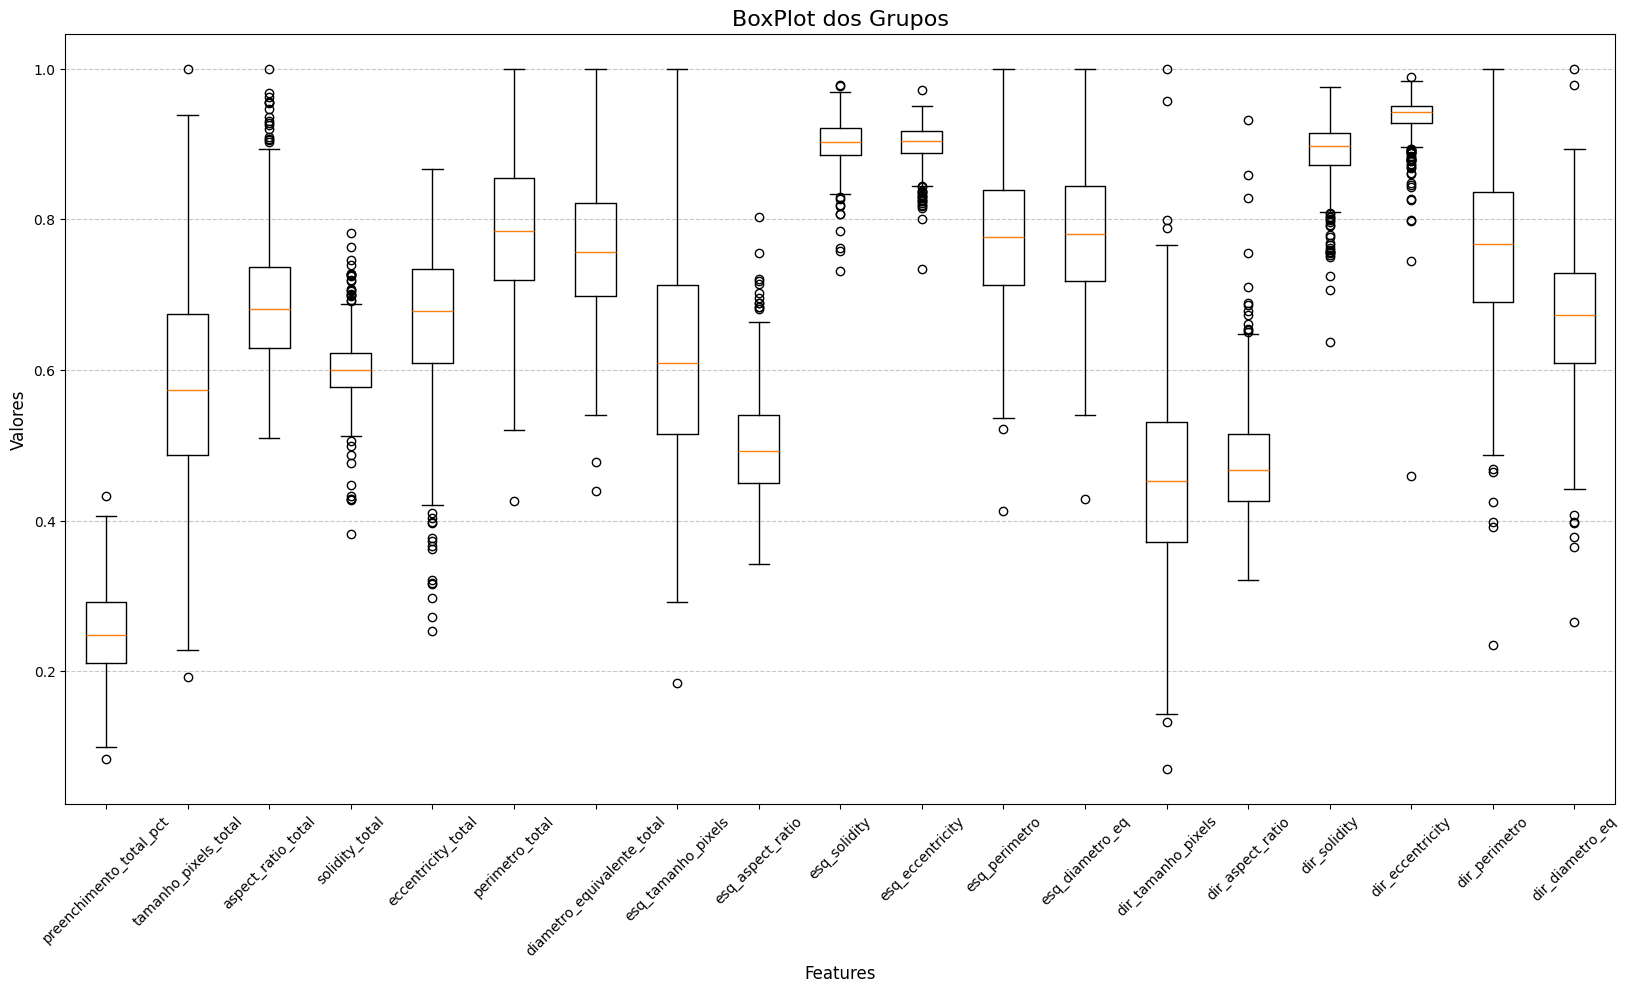

In [145]:
df_plot = df[df.columns[1:]].copy()
for column in df_plot.columns:
    column_max = df_plot[column].max()
    if column_max > 1:
        df_plot[column] /= column_max

plt.figure(figsize=(20, 10))

plt.boxplot([df_plot[col] for col in df_plot.columns], tick_labels=df_plot.columns)

plt.xticks(rotation=45)
plt.title('BoxPlot dos Grupos', fontsize=16)
plt.xlabel('Features', fontsize=12)
plt.ylabel('Valores', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Exibir o gráfico
plt.show()

In [146]:
df_faixas = df[df.columns[1:]].max().reset_index().rename(columns={0:"Max"})
df_faixas = df_faixas.merge(df[df.columns[1:]].min().reset_index().rename(columns={0: "Min"}))
df_faixas = df_faixas.merge(df[df.columns[1:]].quantile(0.05).reset_index().rename(columns={0: "Q05"}))
df_faixas = df_faixas.merge(df[df.columns[1:]].quantile(0.25).reset_index().rename(columns={0: "Q25"}))
df_faixas = df_faixas.merge(df[df.columns[1:]].median().reset_index().rename(columns={0: "Median"}))
df_faixas = df_faixas.merge(df[df.columns[1:]].quantile(0.75).reset_index().rename(columns={0: "Q75"}))
df_faixas = df_faixas.merge(df[df.columns[1:]].quantile(0.95).reset_index().rename(columns={0: "Q95"}))
df_faixas.round(4)

,index,Max,Min,0.05,0.25,Median,0.75,0.95
0,preenchimento_total_pct,0.4331,0.0834,0.1605,0.2111,0.2484,0.2921,0.3453
1,tamanho_pixels_total,28385.0000,5466.0000,10520.5000,13833.0000,16278.0000,19143.5000,22632.0000
2,aspect_ratio_total,1.5374,0.7840,0.8761,0.9672,1.0466,1.1333,1.3227
3,solidity_total,0.7825,0.3819,0.5391,0.5778,0.5996,0.6222,0.6791
4,eccentricity_total,0.8667,0.2533,0.4968,0.6087,0.6788,0.7341,0.8118
5,perimetro_total,1124.4356,479.2031,691.6859,808.2955,882.6184,961.4866,1040.9326
6,diametro_equivalente_total,190.1076,83.4238,115.7372,132.7129,143.9646,156.1226,169.7525
7,esq_tamanho_pixels,14460.0000,2663.0000,5788.0000,7445.5000,8816.5000,10310.5000,12179.5000
8,esq_aspect_ratio,0.8034,0.3427,0.3973,0.4503,0.4920,0.5408,0.6274
9,esq_solidity,0.9778,0.7318,0.8559,0.8859,0.9021,0.9211,0.9432


In [147]:
df_mean = df.set_index("arquivo").mean().round(4)
df_std = df.set_index("arquivo").std().round(4)

df_mean

preenchimento_total_pct           0.2526
tamanho_pixels_total          16557.6237
aspect_ratio_total                1.0629
solidity_total                    0.6014
eccentricity_total                0.6669
perimetro_total                 879.1395
diametro_equivalente_total      144.2260
esq_tamanho_pixels             8896.3887
esq_aspect_ratio                  0.4999
esq_solidity                      0.9012
esq_eccentricity                  0.9004
esq_perimetro                   442.8136
esq_diametro_eq                 105.7308
dir_tamanho_pixels             7659.6484
dir_aspect_ratio                  0.4769
dir_solidity                      0.8900
dir_eccentricity                  0.9356
dir_perimetro                   436.0217
dir_diametro_eq                  97.8511
dtype: float64

In [148]:
cv_values = (df_std / df_mean).round(4)
cv_values

preenchimento_total_pct       0.2280
tamanho_pixels_total          0.2280
aspect_ratio_total            0.1278
solidity_total                0.0737
eccentricity_total            0.1517
perimetro_total               0.1218
diametro_equivalente_total    0.1163
esq_tamanho_pixels            0.2263
esq_aspect_ratio              0.1410
esq_solidity                  0.0321
esq_eccentricity              0.0289
esq_perimetro                 0.1202
esq_diametro_eq               0.1153
dir_tamanho_pixels            0.2644
dir_aspect_ratio              0.1587
dir_solidity                  0.0455
dir_eccentricity              0.0337
dir_perimetro                 0.1387
dir_diametro_eq               0.1364
dtype: float64

## QC Score

* **Solidity:** A maior parte se encontra acima de 85% no pulmão esquerdo e 81,6% no direito, mas existem outliers, permitindo considerar parcialmente valores acima de 70% ou 75%. O máximo está abaixo de 98%, com um outlier no direito em 63% (provável que seja ignorado).

* **Eccentricity:** * O valor máximo observado é quase 99%, adotado como limite superior. A grande maioria dos valores está acima de 85% ($Q_{05} > 85\%$), porém existem outliers chegando a 73% no esquerdo, e a 75% e 46% no direito.

* **Aspect ratio:** Valores sempre acima de 0,30 e bem concentrados na faixa de 0,45 a 0,50. O quantil $Q_{95}$ fica por volta de 0,60 em ambos os lados (podendo ir até 0,70–0,75), com outliers até 0,80 no esquerdo e passando de 0,90 no direito. Critério: considerar integralmente os valores na faixa dos quantis $Q_{00}$ a $Q_{95}$, e parcialmente os valores acima disso.

* **Tamanho:** Valores menores que 20% do máximo (valor exato a definir) serão considerados parcialmente, assim como valores acima do limite superior (menor que 24% no geral e 23% no esquerdo). O $Q_{95}$ do esquerdo está abaixo de 19% e o do direito abaixo de 18%. O $Q_{05}$ de ambos está acima de ~5.000 pixels, ou seja, 7% da imagem (9% no esquerdo). * **Dados ajustados:** O comportamento é semelhante, com o mínimo do esquerdo chegando a 18% (embora o segundo menor já passe de 30%). No direito, há valores distribuídos em todas as faixas, com outliers abaixo de 15% e acima de 80%. É possível definir um mínimo e máximo com base nesses dados ou ignorar a feature no QC.

* **Diâmetro Equivalente:** Sempre acima de 20%, com a grande maioria acima de 50% (valores normalizados pelo máximo observado). No direito, destacam-se apenas 2 outliers acima de 90% e cerca de 6 outliers abaixo de 45%. No esquerdo, há apenas 1 outlier abaixo de 50% (ainda acima de 40%).

* **Perímetro:** 90% dos dados estão entre 330 e 530 pixels, com 95% acima de 330 pixels e máximo por volta de 570 a 575 pixels. Existem mínimos de 235 pixels no esquerdo e 135 pixels no direito.